# ERTH 2001 Lab 1: Earth's Density — Constraining Planetary Interiors

This notebook reproduces Lab 1 from ERTH 2001 (Planet Earth) in Python. The lab was originally an Excel spreadsheet: build a four-shell model of Earth, compute a weighted-average density, and adjust the shells until the whole planet comes out near the known mean density of 5.5 g/cm³. The same steps are followed here, one section at a time, so the concept each step was written to teach is the concept the code shows. Later labs in this series will get their own notebooks and then be collected together.

The numbers below use the same inputs as the completed Excel workbook: an Earth radius of 6,370 km and the shell thicknesses and densities from each step of that spreadsheet. A final check cell confirms that the Python results match those spreadsheet values.

AI used: this notebook was built with help from an AI coding agent.


## Setup

A spherical shell with outer radius $R_\mathrm{top}$ and inner radius $R_\mathrm{bottom}$ has volume

$$V = \tfrac{4}{3}\pi \bigl(R_\mathrm{top}^{3} - R_\mathrm{bottom}^{3}\bigr).$$

The whole-planet average density is a **volume-weighted** average: each shell contributes in proportion to how much space it occupies, not just how thick it is,

$$\bar{\rho} = \frac{\sum_i \rho_i V_i}{\sum_i V_i}.$$

Mass is density times volume, after the units are converted consistently. The helper `shell_table` below does the geometry, the unit conversion, and both kinds of weighted average so each step is a short call.


In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Lab value for Earth's radius (km). The seismic shells in later steps
# are set so their thicknesses add up to this number.
EARTH_RADIUS_KM = 6370.0

# The lab's target mean density for the whole Earth, in g/cm^3.
TARGET_DENSITY = 5.5

# NASA NSSDCA Earth Fact Sheet mass, in kg.
NASA_EARTH_MASS_KG = 5.9722e24

# --- Unit conversion -------------------------------------------------------
# Densities in the lab are given in g/cm^3. Volumes come out in km^3.
# Mass needs kilograms, so we convert density into kg/km^3:
#
#   1 g/cm^3 = 1000 kg/m^3
#   1 km^3   = (10^3 m)^3 = 10^9 m^3
#   1 g/cm^3 = 1000 kg/m^3 * 10^9 m^3/km^3 = 1e12 kg/km^3
#
# The original spreadsheet used the equivalent form
#   (density_g_cm3 / 1000) * (1 / 0.00001) ** 3
# because 1 cm = 0.00001 km, so there are (1e5)^3 = 1e15 cm^3 in a km^3,
# and dividing by 1000 converts grams to kilograms. Both routes equal 1e12.
G_CM3_TO_KG_KM3 = 1.0e12

FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

# Consistent colors for the four named shells (and the two Dante layers).
SHELL_COLORS = {
    "crust": "#C8A56A",
    "mantle": "#B33C2F",
    "outer core": "#E39B1C",
    "inner core": "#F3D768",
    "solid Earth": "#8B5A2B",
    "Hell (thin air)": "#A8B0B8",
}


def shell_table(thicknesses_km, densities, names=None, radius_km=EARTH_RADIUS_KM):
    """Build a table of concentric shells, listed from the surface inward.

    Parameters
    ----------
    thicknesses_km : sequence
        Shell thicknesses in km, outer shell first.
    densities : sequence
        Shell densities in g/cm^3, same order.
    names : sequence, optional
        Labels for the shells. Defaults to crust / mantle / outer core /
        inner core when there are four shells.
    radius_km : float
        Outer radius of the planet in km (lab value: 6370).

    Returns
    -------
    dict
        Arrays for each shell (tops, volumes, masses, ...) plus the
        thickness-weighted and volume-weighted average densities and the
        totals. Thickness-weighted means sum(rho * thickness) / sum(thickness).
        Volume-weighted means sum(rho * volume) / sum(volume).
    """
    thicknesses = np.asarray(thicknesses_km, dtype=float)
    densities = np.asarray(densities, dtype=float)
    if thicknesses.shape != densities.shape:
        raise ValueError("thicknesses_km and densities must have the same length")
    if not np.isclose(thicknesses.sum(), radius_km, rtol=0, atol=1e-9):
        raise ValueError(
            f"shell thicknesses sum to {thicknesses.sum()} km, "
            f"expected radius {radius_km} km"
        )

    n = len(thicknesses)
    if names is None:
        default = ["crust", "mantle", "outer core", "inner core"]
        names = default[:n] if n <= 4 else [f"shell {i+1}" for i in range(n)]
    names = list(names)

    # Depth from the surface to the base of each shell, and the outer
    # radius of each shell. These match the spreadsheet columns
    # "Depth to Base" and "R (top)": R_top of shell i is the sum of
    # that shell's thickness and every shell inside it.
    depths_to_base_km = np.cumsum(thicknesses)
    r_top_km = np.cumsum(thicknesses[::-1])[::-1]
    r_bottom_km = r_top_km - thicknesses  # 0 for the innermost shell

    # Volume of a spherical shell: 4/3 pi (R_top^3 - R_bottom^3).
    volumes_km3 = (4.0 / 3.0) * math.pi * (r_top_km**3 - r_bottom_km**3)

    # Convert g/cm^3 -> kg/km^3, then mass_kg = density * volume.
    densities_kg_km3 = densities * G_CM3_TO_KG_KM3
    masses_kg = densities_kg_km3 * volumes_km3

    total_volume = volumes_km3.sum()
    total_mass = masses_kg.sum()
    thickness_weighted_avg = (densities * thicknesses).sum() / thicknesses.sum()
    volume_weighted_avg = (densities * volumes_km3).sum() / total_volume

    return {
        "names": names,
        "thicknesses_km": thicknesses,
        "depths_to_base_km": depths_to_base_km,
        "r_top_km": r_top_km,
        "r_bottom_km": r_bottom_km,
        "volumes_km3": volumes_km3,
        "densities_g_cm3": densities,
        "densities_kg_km3": densities_kg_km3,
        "masses_kg": masses_kg,
        "total_thickness_km": float(thicknesses.sum()),
        "total_volume_km3": float(total_volume),
        "total_mass_kg": float(total_mass),
        "thickness_weighted_avg": float(thickness_weighted_avg),
        "volume_weighted_avg": float(volume_weighted_avg),
    }


In [2]:
def show_table(result, include_volume=True, include_mass=False):
    """Display a readable table for one model."""
    data = {
        "Shell": result["names"],
        "Thickness (km)": result["thicknesses_km"],
        "Depth to base (km)": result["depths_to_base_km"],
        "R top (km)": result["r_top_km"],
    }
    if include_volume:
        data["Volume (km³)"] = result["volumes_km3"]
    data["Density (g/cm³)"] = result["densities_g_cm3"]
    if include_mass:
        data["Density (kg/km³)"] = result["densities_kg_km3"]
        data["Mass (kg)"] = result["masses_kg"]
    df = pd.DataFrame(data)

    fmt = {
        "Thickness (km)": "{:g}",
        "Depth to base (km)": "{:g}",
        "R top (km)": "{:g}",
        "Volume (km³)": "{:.6e}",
        "Density (g/cm³)": "{:g}",
        "Density (kg/km³)": "{:.6e}",
        "Mass (kg)": "{:.6e}",
    }
    display(df.style.format(fmt).hide(axis="index"))
    return df


def _colors_for(labels):
    return [SHELL_COLORS.get(name, "#7F8C8D") for name in labels]


def pie_pair(labels, left_values, right_values, left_title, right_title, filename):
    """Two labeled pie charts, saved under figures/ and shown in the notebook."""
    fig, axes = plt.subplots(1, 2, figsize=(12.2, 6.4))
    colors = _colors_for(labels)

    for ax, values, title in (
        (axes[0], left_values, left_title),
        (axes[1], right_values, right_title),
    ):
        values = np.asarray(values, dtype=float)
        total = values.sum()
        wedges, _, autotexts = ax.pie(
            values,
            colors=colors,
            startangle=90,
            counterclock=False,
            wedgeprops=dict(edgecolor="white", linewidth=1.2),
            autopct=lambda p: f"{p:.1f}%" if p >= 4 else "",
            pctdistance=0.62,
            textprops={"fontsize": 10},
        )
        # Dark slices get white percentage labels; light slices get dark labels.
        for wedge, text in zip(wedges, autotexts):
            rgba = wedge.get_facecolor()
            lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            text.set_color("white" if lum < 0.55 else "#1a1a1a")
            text.set_fontweight("bold")

        ax.set_title(title, fontsize=13, pad=14, fontweight="bold", color="#1a1a1a")
        def _fmt_val(val):
            # Keep 1592.5 as 1592.5 (not 1592). Use scientific notation
            # only for the very large volume and mass figures.
            if abs(val) >= 1.0e5 or (val != 0 and abs(val) < 1.0e-2):
                return f"{val:.4e}"
            return f"{val:.6g}"

        legend_labels = [
            f"{name}  —  {_fmt_val(val)}  ({100.0 * val / total:.1f}%)"
            for name, val in zip(labels, values)
        ]
        ax.legend(
            wedges,
            legend_labels,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.06),
            frameon=False,
            fontsize=9,
        )

    fig.tight_layout()
    out = FIGDIR / filename
    fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"saved {out}")


## Step 1 — Four equal shells, averaged by thickness

The first model is a sketch. Earth is split into four concentric shells of equal thickness, 1,592.5 km each (6,370 / 4). The shells are given a first-guess set of densities, increasing toward the center: 2.8, 5, 7, and 9 g/cm³.

Because every shell has the same thickness, a thickness-weighted average is the same as an ordinary arithmetic mean: add the four densities and divide by four, or equivalently compute $\sum \rho_i t_i / \sum t_i$. That number is a starting point, not a physically careful mean. A kilometer of crust at the surface encloses much more volume than a kilometer of inner core, so treating thickness as the weight over-represents the dense interior. The next step puts the sphere's volume formula in. The density pie on the right is only a picture of the relative density values; unlike the thickness pie, it is not a partition of the planet.


Earth radius (sum of thicknesses): 6370 km
Thickness-weighted average density: 5.9500 g/cm³
  (equal shells, so this is also the arithmetic mean: 5.9500 g/cm³)


Shell,Thickness (km),Depth to base (km),R top (km),Density (g/cm³)
crust,1592.5,1592.5,6370,2.8
mantle,1592.5,3185,4777.5,5
outer core,1592.5,4777.5,3185,7
inner core,1592.5,6370,1592.5,9


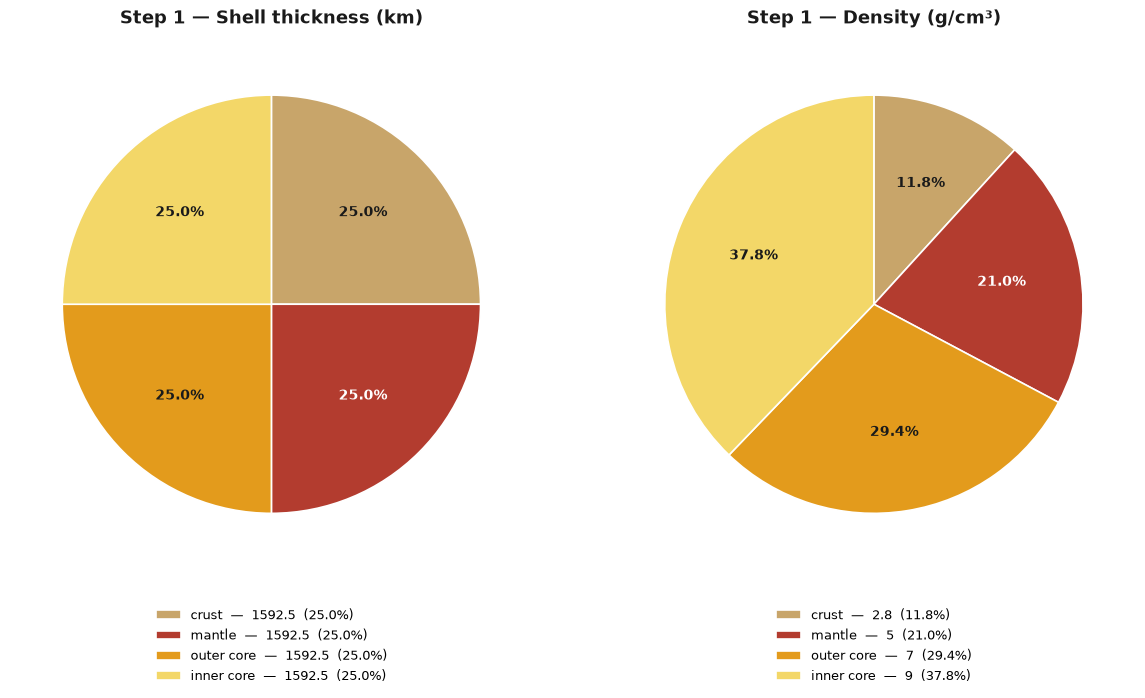

saved figures/step1_thickness_density.png


In [3]:
step1 = shell_table(
    thicknesses_km=[1592.5, 1592.5, 1592.5, 1592.5],
    densities=[2.8, 5.0, 7.0, 9.0],
)

print(f"Earth radius (sum of thicknesses): {step1['total_thickness_km']:g} km")
print(f"Thickness-weighted average density: {step1['thickness_weighted_avg']:.4f} g/cm³")
print(
    "  (equal shells, so this is also the arithmetic mean: "
    f"{step1['densities_g_cm3'].mean():.4f} g/cm³)"
)

show_table(step1, include_volume=False, include_mass=False)

pie_pair(
    labels=step1["names"],
    left_values=step1["thicknesses_km"],
    right_values=step1["densities_g_cm3"],
    left_title="Step 1 — Shell thickness (km)",
    right_title="Step 1 — Density (g/cm³)",
    filename="step1_thickness_density.png",
)


## Step 2 — Weight the same shells by volume

The thicknesses and densities are unchanged. What changes is the weight in the average. Each shell is now a spherical shell whose volume is $\tfrac{4}{3}\pi(R_\mathrm{top}^{3}-R_\mathrm{bottom}^{3})$, and the mean density is $\sum \rho_i V_i / \sum V_i$.

The outer shell has a much larger volume than the inner core, even though both are 1,592.5 km thick. The low-density crust therefore contributes far more to the average than it did in Step 1, and the whole-planet density drops. The two pie charts below make that contrast visible: equal thickness slices on the left, very unequal volume slices on the right. The total volume of the planet is the same in every later step, because the outer radius does not change.


R (top) of each shell, surface to center: [6370.  4777.5 3185.  1592.5]
Total volume: 1.082697e+12 km³
Volume-weighted average density: 4.009375 g/cm³
Step 1 thickness-weighted average was 5.9500 g/cm³ — the mean falls once outer volume is counted properly.


Shell,Thickness (km),Depth to base (km),R top (km),Volume (km³),Density (g/cm³)
crust,1592.5,1592.5,6370,6.259342e+11,2.8
mantle,1592.5,3185,4777.5,3.214257e+11,5
outer core,1592.5,4777.5,3185,1.184200e+11,7
inner core,1592.5,6370,1592.5,1.691714e+10,9


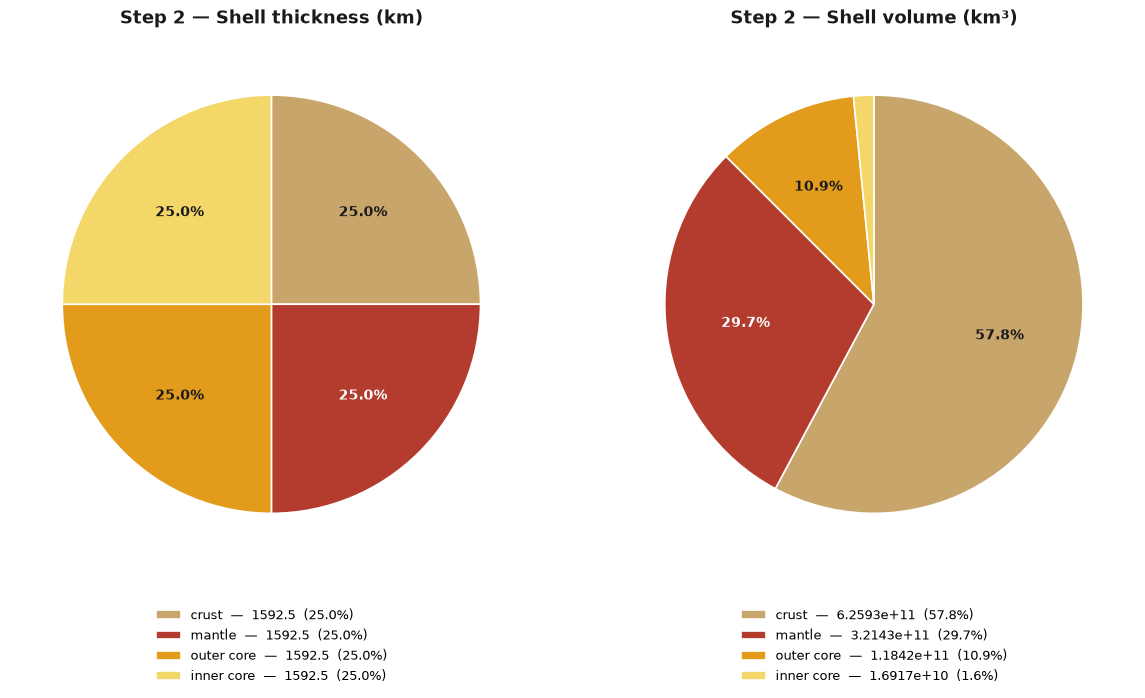

saved figures/step2_thickness_volume.png


In [4]:
step2 = shell_table(
    thicknesses_km=[1592.5, 1592.5, 1592.5, 1592.5],
    densities=[2.8, 5.0, 7.0, 9.0],
)

print(f"R (top) of each shell, surface to center: {step2['r_top_km']}")
print(f"Total volume: {step2['total_volume_km3']:.6e} km³")
print(f"Volume-weighted average density: {step2['volume_weighted_avg']:.6f} g/cm³")
print(
    "Step 1 thickness-weighted average was "
    f"{step1['thickness_weighted_avg']:.4f} g/cm³ — "
    "the mean falls once outer volume is counted properly."
)

show_table(step2, include_volume=True, include_mass=False)

pie_pair(
    labels=step2["names"],
    left_values=step2["thicknesses_km"],
    right_values=step2["volumes_km3"],
    left_title="Step 2 — Shell thickness (km)",
    right_title="Step 2 — Shell volume (km³)",
    filename="step2_thickness_volume.png",
)


## Step 3 — Move the boundaries to the seismic discontinuities

Equal shells were only a first sketch. The real Earth is divided by seismic discontinuities: the base of the crust, the core-mantle boundary, and the inner-core boundary. This step keeps the same first-guess densities and changes only the thicknesses, to 50, 2,840, 2,260, and 1,220 km (tops at 6,370, 6,320, 3,480, and 1,220 km).

The crust is now a thin skin, and the mantle is the bulky shell. Volume-weighted, the average density rises relative to Step 2, because so much of the planet's volume now sits in the mantle rather than in a thick, low-density "crust." The total volume is unchanged: it is still the volume of a sphere of radius 6,370 km.


R (top) of each shell: [6370. 6320. 3480. 1220.]
Total volume: 1.082697e+12 km³
  (same as Step 2, to numerical precision: True)
Volume-weighted average density: 5.288750 g/cm³


Shell,Thickness (km),Depth to base (km),R top (km),Volume (km³),Density (g/cm³)
crust,50,50,6370,2.529562e+10,2.8
mantle,2840,2890,6320,8.808681e+11,5
outer core,2260,5150,3480,1.689270e+11,7
inner core,1220,6370,1220,7.606206e+09,9


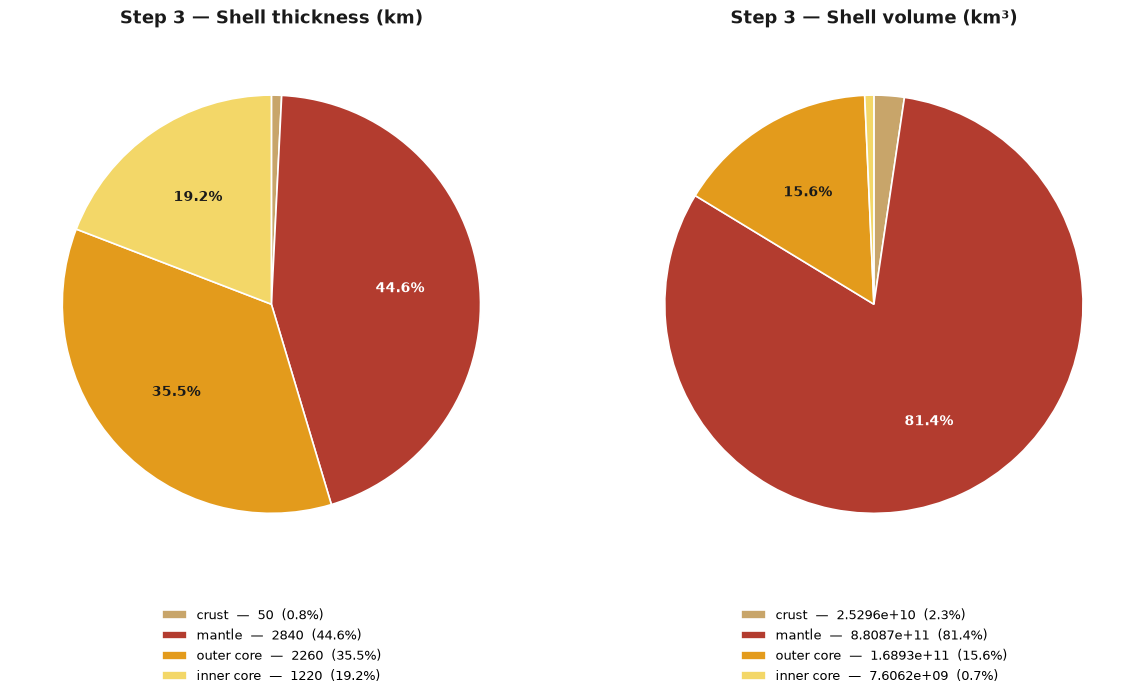

saved figures/step3_thickness_volume.png


In [5]:
step3 = shell_table(
    thicknesses_km=[50.0, 2840.0, 2260.0, 1220.0],
    densities=[2.8, 5.0, 7.0, 9.0],
)

print(f"R (top) of each shell: {step3['r_top_km']}")
print(f"Total volume: {step3['total_volume_km3']:.6e} km³")
print(
    "  (same as Step 2, to numerical precision: "
    f"{np.isclose(step3['total_volume_km3'], step2['total_volume_km3'])})"
)
print(f"Volume-weighted average density: {step3['volume_weighted_avg']:.6f} g/cm³")

show_table(step3, include_volume=True, include_mass=False)

pie_pair(
    labels=step3["names"],
    left_values=step3["thicknesses_km"],
    right_values=step3["volumes_km3"],
    left_title="Step 3 — Shell thickness (km)",
    right_title="Step 3 — Shell volume (km³)",
    filename="step3_thickness_volume.png",
)


## Step 4 — Adjust densities to match the known mean

The shell thicknesses now follow the seismic boundaries, which is the more realistic geometry. The remaining lever is density. This is forward modeling: change the input densities, recompute the volume-weighted mean, and look for a combination that lands near the lab's target of 5.5 g/cm³.

The densities used here are the ones from the completed Excel lab: 2.8, 4.5, 11.1, and 13 g/cm³ for the crust, mantle, outer core, and inner core. With those values the mean is close to the 5.5 g/cm³ target. Each shell's mass then follows from

$$m_i = \rho_i V_i$$

after converting $\rho$ from g/cm³ into kg/km³ (the factor of $10^{12}$ described in the setup). The sum of the shell masses is the model Earth's mass, which can be compared with the NASA value of $5.9722\times 10^{24}$ kg.

The pie charts below compare how volume and mass are distributed. A large, moderate-density shell can hold more mass than a smaller, denser one, so the two pies need not look the same.


Volume-weighted average density: 5.549757 g/cm³
  target mean density:           5.5 g/cm³
  difference from target:        +0.049757 g/cm³ (+0.90%)
Total mass:                      6.008704e+24 kg
  NASA Earth mass:               5.9722e+24 kg
  difference from NASA:          +3.650441e+22 kg (+0.61%)


Shell,Thickness (km),Depth to base (km),R top (km),Volume (km³),Density (g/cm³),Density (kg/km³),Mass (kg)
crust,50,50,6370,2.529562e+10,2.8,2.800000e+12,7.082774e+22
mantle,2840,2890,6320,8.808681e+11,4.5,4.500000e+12,3.963907e+24
outer core,2260,5150,3480,1.689270e+11,11.1,1.110000e+13,1.875089e+24
inner core,1220,6370,1220,7.606206e+09,13,1.300000e+13,9.888068e+22


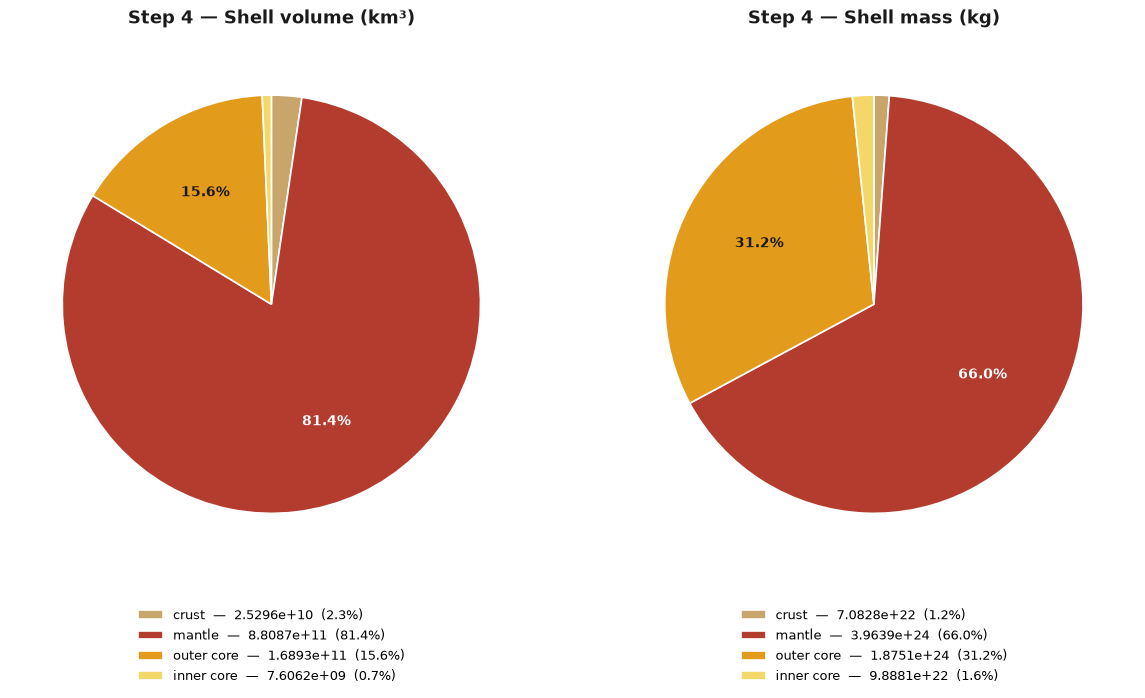

saved figures/step4_volume_mass.png


In [6]:
step4 = shell_table(
    thicknesses_km=[50.0, 2840.0, 2260.0, 1220.0],
    densities=[2.8, 4.5, 11.1, 13.0],
)

print(f"Volume-weighted average density: {step4['volume_weighted_avg']:.6f} g/cm³")
print(f"  target mean density:           {TARGET_DENSITY:.1f} g/cm³")
print(
    f"  difference from target:        "
    f"{step4['volume_weighted_avg'] - TARGET_DENSITY:+.6f} g/cm³ "
    f"({100.0 * (step4['volume_weighted_avg'] / TARGET_DENSITY - 1.0):+.2f}%)"
)
print(f"Total mass:                      {step4['total_mass_kg']:.6e} kg")
print(f"  NASA Earth mass:               {NASA_EARTH_MASS_KG:.4e} kg")
print(
    f"  difference from NASA:          "
    f"{step4['total_mass_kg'] - NASA_EARTH_MASS_KG:+.6e} kg "
    f"({100.0 * (step4['total_mass_kg'] / NASA_EARTH_MASS_KG - 1.0):+.2f}%)"
)

show_table(step4, include_volume=True, include_mass=True)

pie_pair(
    labels=step4["names"],
    left_values=step4["volumes_km3"],
    right_values=step4["masses_kg"],
    left_title="Step 4 — Shell volume (km³)",
    right_title="Step 4 — Shell mass (kg)",
    filename="step4_volume_mass.png",
)


## Dante's Inferno model

The last model is a what-if, built on a copy of the Step 4 spreadsheet. In *Inferno*, Hell sits at the center of the Earth. Here it is treated as a hollow cavity of radius 1,000 km, filled with thin air at 0.001092 g/cm³. The planet's outer radius stays 6,370 km, and the solid part is assigned the density of crustal rock, 2.8 g/cm³.

In the workbook that becomes four shells: a 420 km crust and a 4,950 km "mantle," both at 2.8 g/cm³, then two 500 km shells that make up the 1,000 km cavity. The lab asks for pie charts of the **two** layers — solid Earth versus the hollow interior — so those are the plots below. The four-shell table is still computed, so the totals can be checked against the spreadsheet.

Because volume grows with the cube of radius, a 1,000 km hole is only a small fraction of Earth's volume. The average density is therefore close to the density of the solid rock, not halfway between rock and air.


Volume-weighted average density: 2.789171 g/cm³
Total mass:                      3.019827e+24 kg
Hell cavity radius:              1000 km
Hell volume fraction:            0.39% of Earth
  (for comparison, (1000/6370)^3 = 0.39%)


Shell,Thickness (km),Depth to base (km),R top (km),Volume (km³),Density (g/cm³),Density (kg/km³),Mass (kg)
crust,420,420,6370,2.003497e+11,2.8,2.800000e+12,5.609793e+23
mantle,4950,5370,5950,8.781584e+11,2.8,2.800000e+12,2.458844e+24
outer core,500,5870,1000,3.665191e+09,0.001092,1.092000e+09,4.002389e+18
inner core,500,6370,500,5.235988e+08,0.001092,1.092000e+09,5.717699e+17


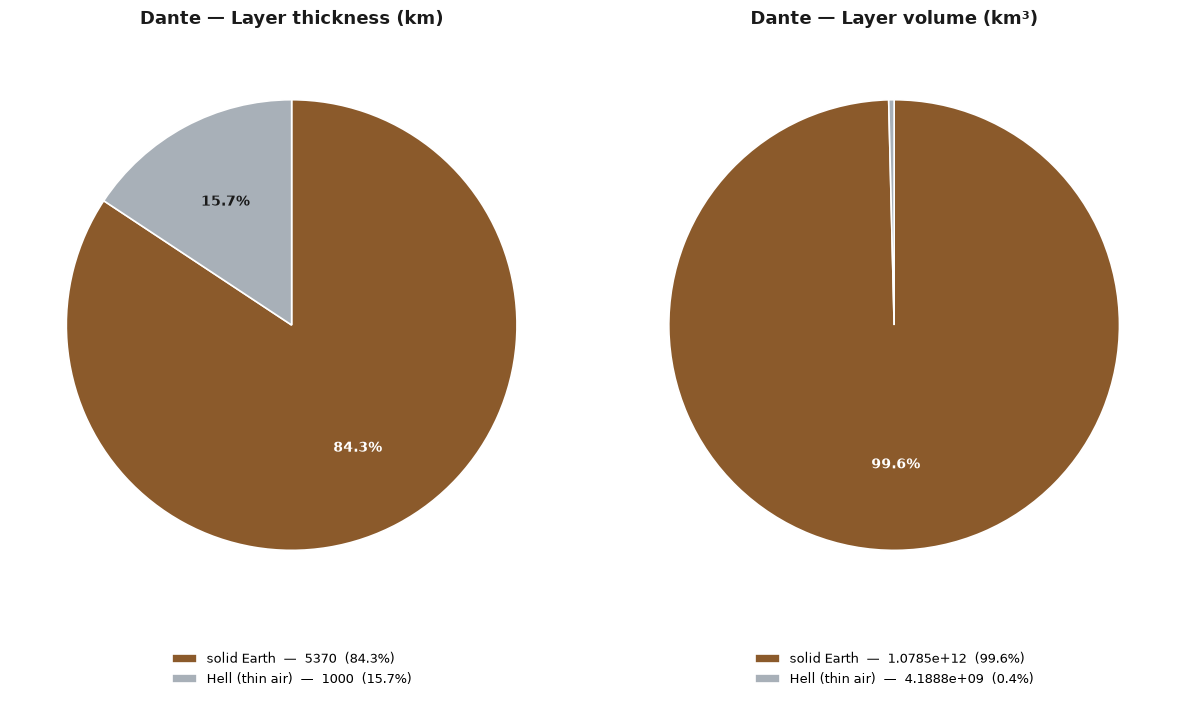

saved figures/dante_thickness_volume.png


In [7]:
dante = shell_table(
    thicknesses_km=[420.0, 4950.0, 500.0, 500.0],
    densities=[2.8, 2.8, 0.001092, 0.001092],
)

# Two-layer grouping used for the lab's Dante pie charts:
# solid Earth = crust + mantle, Hell = the 1000 km air-filled cavity.
solid_thickness = dante["thicknesses_km"][:2].sum()
hell_thickness = dante["thicknesses_km"][2:].sum()
solid_volume = dante["volumes_km3"][:2].sum()
hell_volume = dante["volumes_km3"][2:].sum()
hell_volume_fraction = hell_volume / dante["total_volume_km3"]

print(f"Volume-weighted average density: {dante['volume_weighted_avg']:.6f} g/cm³")
print(f"Total mass:                      {dante['total_mass_kg']:.6e} kg")
print(f"Hell cavity radius:              1000 km")
print(f"Hell volume fraction:            {100.0 * hell_volume_fraction:.2f}% of Earth")
print(
    f"  (for comparison, (1000/6370)^3 = "
    f"{100.0 * (1000.0 / EARTH_RADIUS_KM) ** 3:.2f}%)"
)

show_table(dante, include_volume=True, include_mass=True)

pie_pair(
    labels=["solid Earth", "Hell (thin air)"],
    left_values=[solid_thickness, hell_thickness],
    right_values=[solid_volume, hell_volume],
    left_title="Dante — Layer thickness (km)",
    right_title="Dante — Layer volume (km³)",
    filename="dante_thickness_volume.png",
)


## Summary of the models

Every model below uses the same outer radius, 6,370 km, and therefore the same total volume. What changes is how that volume is divided and what density each shell is given. The target mean density is 5.5 g/cm³. The mass column uses the spherical-shell volumes and the unit conversion from the setup, including in Steps 1–3, where the original spreadsheet had not yet added a mass column.


Model,Average density (g/cm³),vs 5.5 g/cm³ target,Mass (kg),vs NASA mass (kg)
"Step 1 (equal shells, thickness-weighted)",5.950000,+0.450000,4.340938e+24,-1.631262e+24
"Step 2 (equal shells, volume-weighted)",4.009375,-1.490625,4.340938e+24,-1.631262e+24
Step 3 (seismic thicknesses),5.288750,-0.211250,5.726113e+24,-2.460869e+23
"Step 4 (seismic thicknesses, adjusted densities)",5.549757,+0.049757,6.008704e+24,+3.650441e+22
Dante (hollow 1000 km Hell),2.789171,-2.710829,3.019827e+24,-2.952373e+24


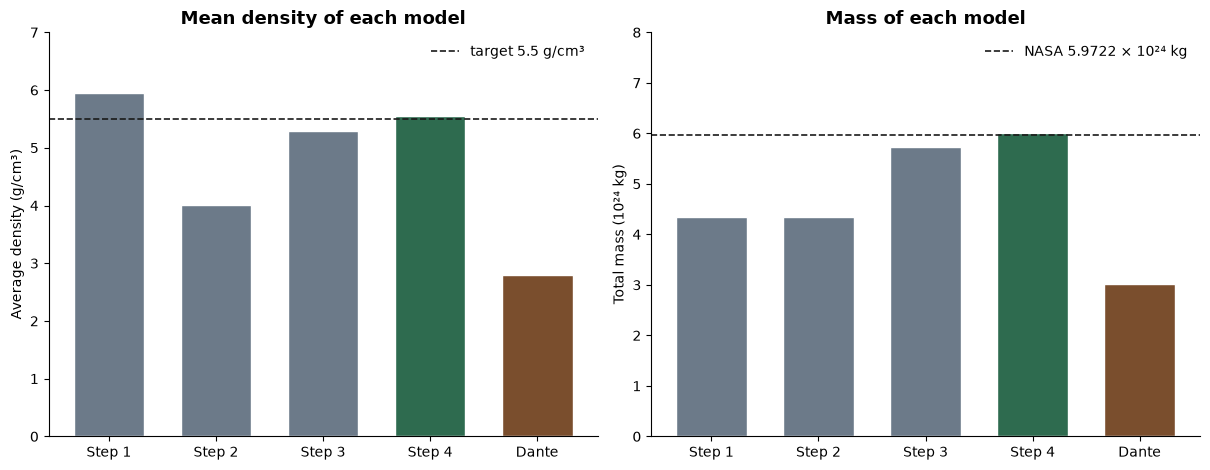

saved figures/summary_density_mass.png


In [8]:
models = [
    ("Step 1 (equal shells, thickness-weighted)", step1, "thickness"),
    ("Step 2 (equal shells, volume-weighted)", step2, "volume"),
    ("Step 3 (seismic thicknesses)", step3, "volume"),
    ("Step 4 (seismic thicknesses, adjusted densities)", step4, "volume"),
    ("Dante (hollow 1000 km Hell)", dante, "volume"),
]

rows = []
for label, result, kind in models:
    avg = (
        result["thickness_weighted_avg"]
        if kind == "thickness"
        else result["volume_weighted_avg"]
    )
    rows.append(
        {
            "Model": label,
            "Average density (g/cm³)": avg,
            "vs 5.5 g/cm³ target": avg - TARGET_DENSITY,
            "Mass (kg)": result["total_mass_kg"],
            "vs NASA mass (kg)": result["total_mass_kg"] - NASA_EARTH_MASS_KG,
        }
    )

summary = pd.DataFrame(rows)
display(
    summary.style.format(
        {
            "Average density (g/cm³)": "{:.6f}",
            "vs 5.5 g/cm³ target": "{:+.6f}",
            "Mass (kg)": "{:.6e}",
            "vs NASA mass (kg)": "{:+.6e}",
        }
    ).hide(axis="index")
)

# Side-by-side bars: average density vs the 5.5 target, and mass vs NASA.
short_names = ["Step 1", "Step 2", "Step 3", "Step 4", "Dante"]
avgs = [row["Average density (g/cm³)"] for row in rows]
masses = [row["Mass (kg)"] for row in rows]
bar_colors = ["#6C7A89", "#6C7A89", "#6C7A89", "#2E6B4F", "#7A4E2D"]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8))

axes[0].bar(short_names, avgs, color=bar_colors, width=0.66, edgecolor="white")
axes[0].axhline(
    TARGET_DENSITY, color="#1a1a1a", linestyle="--", linewidth=1.2, label="target 5.5 g/cm³"
)
axes[0].set_ylabel("Average density (g/cm³)")
axes[0].set_title("Mean density of each model", fontsize=13, fontweight="bold")
axes[0].legend(frameon=False, loc="upper right")
axes[0].set_ylim(0, 7)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

axes[1].bar(
    short_names, np.array(masses) / 1e24, color=bar_colors, width=0.66, edgecolor="white"
)
axes[1].axhline(
    NASA_EARTH_MASS_KG / 1e24,
    color="#1a1a1a",
    linestyle="--",
    linewidth=1.2,
    label="NASA 5.9722 × 10²⁴ kg",
)
axes[1].set_ylabel("Total mass (10²⁴ kg)")
axes[1].set_title("Mass of each model", fontsize=13, fontweight="bold")
axes[1].legend(frameon=False, loc="upper right")
axes[1].set_ylim(0, 8)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGDIR / "summary_density_mass.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("saved figures/summary_density_mass.png")


## Extra (not part of the lab): Step 4 shells compared with PREM

The original lab stops at the four-shell models above. This section is an optional comparison, added after the fact.

PREM, the Preliminary Reference Earth Model (Dziewonski & Anderson, 1981), describes density as a polynomial in radius inside each of several layers,

$$\rho(x) = a + bx + cx^{2} + dx^{3},\qquad x = r / 6371\,\mathrm{km},$$

with $\rho$ in g/cm³. The coefficients below are those published values. Averaging PREM over one of the lab's Step 3/4 shells means taking the volume-weighted mean of $\rho(r)$ between that shell's inner and outer radii (using the lab's 6,370 km surface, not PREM's 6,371 km). The 50 km "crust" shell in the lab is thicker than PREM's crust, so that average also includes some upper mantle and comes out higher than a typical crustal density.


Shell,Lab R top (km),Lab R bottom (km),Step 4 density (g/cm³),PREM average (g/cm³),Step 4 − PREM (g/cm³)
crust,6370,6320,2.80,3.01,-0.21
mantle,6320,3480,4.50,4.49,+0.01
outer core,3480,1220,11.10,10.90,+0.20
inner core,1220,0,13.00,12.89,+0.11


PREM averages over the lab shells, rounded: 3.01, 4.49, 10.90, 12.89 g/cm³.


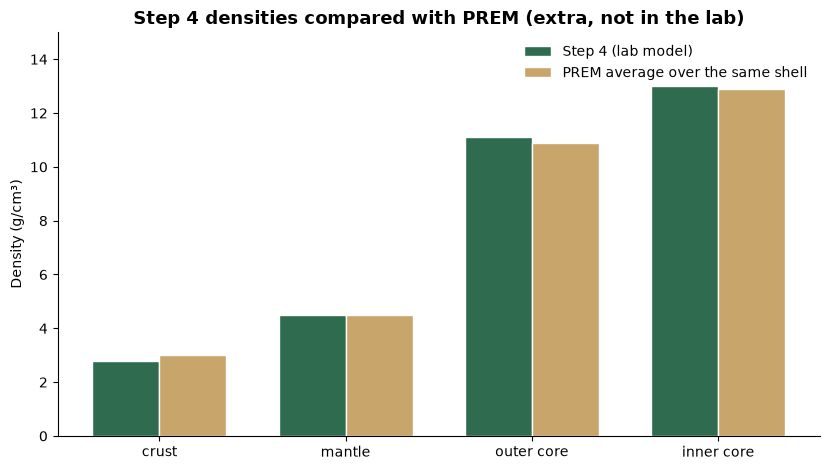

saved figures/prem_vs_step4.png


In [9]:
# PREM isotropic density polynomials, Dziewonski & Anderson (1981), Table 1.
# rho(x) = a + b x + c x^2 + d x^3, with x = r / 6371 km, rho in g/cm^3.
PREM_R0_KM = 6371.0
PREM_LAYERS = [
    # name, r_min_km, r_max_km, (a, b, c, d)
    ("inner core",              0.0,    1221.5, (13.0885,  0.0,    -8.8381,  0.0)),
    ("outer core",              1221.5, 3480.0, (12.5815, -1.2638, -3.6426, -5.5281)),
    ("lower mantle",            3480.0, 5701.0, ( 7.9565, -6.4761,  5.5283, -3.0807)),
    ("transition zone",         5701.0, 5771.0, ( 5.3197, -1.4836,  0.0,     0.0)),
    ("transition zone",         5771.0, 5971.0, (11.2494, -8.0298,  0.0,     0.0)),
    ("upper mantle",            5971.0, 6151.0, ( 7.1089, -3.8045,  0.0,     0.0)),
    ("upper mantle (LVZ + lid)",6151.0, 6346.6, ( 2.6910,  0.6924,  0.0,     0.0)),
    ("lower crust",             6346.6, 6356.0, ( 2.900,   0.0,     0.0,     0.0)),
    ("upper crust",             6356.0, 6368.0, ( 2.600,   0.0,     0.0,     0.0)),
    ("ocean",                   6368.0, 6371.0, ( 1.020,   0.0,     0.0,     0.0)),
]


def _prem_rho_r2_antideriv(x, coeffs):
    """Antiderivative of rho(x) * x^2, used for a volume-weighted mean.

    int rho(r) r^2 dr = R0^3 * int rho(x) x^2 dx, with x = r / R0.
    int (a + b x + c x^2 + d x^3) x^2 dx = a x^3/3 + b x^4/4 + c x^5/5 + d x^6/6.
    """
    a, b, c, d = coeffs
    return a * x**3 / 3.0 + b * x**4 / 4.0 + c * x**5 / 5.0 + d * x**6 / 6.0


def prem_average(r_inner_km, r_outer_km):
    """Volume-weighted PREM density (g/cm^3) between two radii in km."""
    # int rho r^2 dr, accumulated piecewise over the PREM layers that
    # overlap this radius window. The window is clipped to PREM's range.
    numerator = 0.0
    for _name, rmin, rmax, coeffs in PREM_LAYERS:
        lo = max(r_inner_km, rmin)
        hi = min(r_outer_km, rmax)
        if hi <= lo:
            continue
        x_lo = lo / PREM_R0_KM
        x_hi = hi / PREM_R0_KM
        numerator += (PREM_R0_KM**3) * (
            _prem_rho_r2_antideriv(x_hi, coeffs) - _prem_rho_r2_antideriv(x_lo, coeffs)
        )
    denominator = (r_outer_km**3 - r_inner_km**3) / 3.0
    return numerator / denominator


# Average PREM over the lab's Step 3/4 shells (radii 6370, 6320, 3480, 1220, 0).
prem_avgs = np.array(
    [prem_average(r_in, r_out) for r_in, r_out in zip(step4["r_bottom_km"], step4["r_top_km"])]
)

prem_df = pd.DataFrame(
    {
        "Shell": step4["names"],
        "Lab R top (km)": step4["r_top_km"],
        "Lab R bottom (km)": step4["r_bottom_km"],
        "Step 4 density (g/cm³)": step4["densities_g_cm3"],
        "PREM average (g/cm³)": prem_avgs,
        "Step 4 − PREM (g/cm³)": step4["densities_g_cm3"] - prem_avgs,
    }
)
display(
    prem_df.style.format(
        {
            "Lab R top (km)": "{:g}",
            "Lab R bottom (km)": "{:g}",
            "Step 4 density (g/cm³)": "{:.2f}",
            "PREM average (g/cm³)": "{:.2f}",
            "Step 4 − PREM (g/cm³)": "{:+.2f}",
        }
    ).hide(axis="index")
)
print(
    "PREM averages over the lab shells, rounded: "
    + ", ".join(f"{val:.2f}" for val in prem_avgs)
    + " g/cm³."
)

x = np.arange(len(step4["names"]))
width = 0.36
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.bar(
    x - width / 2,
    step4["densities_g_cm3"],
    width,
    label="Step 4 (lab model)",
    color="#2E6B4F",
    edgecolor="white",
)
ax.bar(
    x + width / 2,
    prem_avgs,
    width,
    label="PREM average over the same shell",
    color="#C8A56A",
    edgecolor="white",
)
ax.set_xticks(x)
ax.set_xticklabels(step4["names"])
ax.set_ylabel("Density (g/cm³)")
ax.set_title(
    "Step 4 densities compared with PREM (extra, not in the lab)",
    fontsize=13,
    fontweight="bold",
)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(0, 15)
fig.tight_layout()
fig.savefig(FIGDIR / "prem_vs_step4.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("saved figures/prem_vs_step4.png")


## Check against the Excel workbook

The constants in the next cell are the values stored in the completed lab spreadsheet. Each assertion requires the relative difference to be at most $10^{-6}$. If this cell runs without error, the Python model has reproduced those spreadsheet results.


In [10]:
def assert_close(name, got, expected, rtol=1e-6):
    got = float(got)
    expected = float(expected)
    rel = abs(got - expected) / abs(expected) if expected != 0 else abs(got)
    assert rel <= rtol, f"{name}: got {got}, expected {expected}, relative error {rel:.3e}"
    print(f"ok  {name}: {got}   (relative error {rel:.2e})")


# --- Step 1 (thickness-weighted) ------------------------------------------
assert_close("step 1 thickness-weighted average", step1["thickness_weighted_avg"], 5.95)
assert_close("step 1 total thickness", step1["total_thickness_km"], 6370.0)
assert_close(
    "step 1 sumproduct (km * g/cm^3)",
    (step1["thicknesses_km"] * step1["densities_g_cm3"]).sum(),
    37901.5,
)

# --- Step 2 (equal shells, volume-weighted) --------------------------------
for name, got, expected in zip(
    step2["names"],
    step2["r_top_km"],
    [6370.0, 4777.5, 3185.0, 1592.5],
):
    assert_close(f"step 2 R top ({name})", got, expected)

for name, got, expected in zip(
    step2["names"],
    step2["volumes_km3"],
    [625934164061.095, 321425651815.1569, 118419976984.5315, 16917139569.218784],
):
    assert_close(f"step 2 volume ({name})", got, expected)

assert_close("step 2 total volume", step2["total_volume_km3"], 1082696932430.0022)
assert_close("step 2 volume-weighted average", step2["volume_weighted_avg"], 4.009375)

# --- Step 3 (seismic thicknesses) ------------------------------------------
for name, got, expected in zip(
    step3["names"],
    step3["r_top_km"],
    [6370.0, 6320.0, 3480.0, 1220.0],
):
    assert_close(f"step 3 R top ({name})", got, expected)

for name, got, expected in zip(
    step3["names"],
    step3["volumes_km3"],
    [25295622335.831463, 880868131455.9337, 168926972322.456, 7606206315.780957],
):
    assert_close(f"step 3 volume ({name})", got, expected)

assert_close("step 3 total volume", step3["total_volume_km3"], 1082696932430.0022)
assert_close("step 3 volume-weighted average", step3["volume_weighted_avg"], 5.288749687382548)

# --- Step 4 (adjusted densities) -------------------------------------------
assert_close("step 4 volume-weighted average", step4["volume_weighted_avg"], 5.549756565293413)
assert_close("step 4 total mass", step4["total_mass_kg"], 6.00870440897644e24)
for name, got, expected in zip(
    step4["names"],
    step4["masses_kg"],
    [7.082774254032806e22, 3.963906591551699e24, 1.8750893927792606e24, 9.888068210515238e22],
):
    assert_close(f"step 4 mass ({name})", got, expected)

# --- Dante -----------------------------------------------------------------
for name, got, expected in zip(
    dante["names"],
    dante["r_top_km"],
    [6370.0, 5950.0, 1000.0, 500.0],
):
    assert_close(f"dante R top ({name})", got, expected)

for name, got, expected in zip(
    dante["names"],
    dante["volumes_km3"],
    [200349743341.54855, 878158398883.6672, 3665191429.1880918, 523598775.5982988],
):
    assert_close(f"dante volume ({name})", got, expected)

assert_close("dante volume-weighted average", dante["volume_weighted_avg"], 2.7891714494949333)
assert_close("dante total mass", dante["total_mass_kg"], 3.0198273723895064e24)

# --- PREM extra: previously computed averages over the Step 3 shells -------
for name, got, expected in zip(
    step4["names"],
    prem_avgs,
    [3.005894, 4.492241, 10.901006, 12.894047],
):
    assert_close(f"PREM average over lab {name} shell", got, expected, rtol=1e-5)

print("\nAll checks passed: Python results match the Excel workbook to 1e-6 relative.")


ok  step 1 thickness-weighted average: 5.95   (relative error 0.00e+00)
ok  step 1 total thickness: 6370.0   (relative error 0.00e+00)
ok  step 1 sumproduct (km * g/cm^3): 37901.5   (relative error 0.00e+00)
ok  step 2 R top (crust): 6370.0   (relative error 0.00e+00)
ok  step 2 R top (mantle): 4777.5   (relative error 0.00e+00)
ok  step 2 R top (outer core): 3185.0   (relative error 0.00e+00)
ok  step 2 R top (inner core): 1592.5   (relative error 0.00e+00)
ok  step 2 volume (crust): 625934164061.095   (relative error 0.00e+00)
ok  step 2 volume (mantle): 321425651815.1569   (relative error 0.00e+00)
ok  step 2 volume (outer core): 118419976984.5315   (relative error 0.00e+00)
ok  step 2 volume (inner core): 16917139569.218784   (relative error 0.00e+00)
ok  step 2 total volume: 1082696932430.0022   (relative error 0.00e+00)
ok  step 2 volume-weighted average: 4.009375   (relative error 0.00e+00)
ok  step 3 R top (crust): 6370.0   (relative error 0.00e+00)
ok  step 3 R top (mantle): 6